In [1]:
import os, zlib, base64
import pandas as pd
import numpy as np

if not os.path.exists("house_price_regression_dataset.csv"):
    with open("house_price_regression_dataset.csv", "wb") as _f:
        _f.write(zlib.decompress(base64.b64decode("")))

df = pd.read_csv("house_price_regression_dataset.csv")
df.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


In [2]:
from sklearn.model_selection import train_test_split
X=df[['Square_Footage','Num_Bedrooms','Num_Bathrooms','Year_Built','Lot_Size','Garage_Size','Neighborhood_Quality']]
y=df['House_Price']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [3]:
(X_test)

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality
521,4012,3,1,2016,2.098092,1,5
737,2310,3,1,1988,1.369622,1,4
740,4708,1,3,1962,1.792970,1,8
660,4932,2,1,1972,4.479598,1,2
411,3646,1,1,1994,3.980987,0,9
...,...,...,...,...,...,...,...
408,3767,5,3,1981,1.520335,2,4
332,616,2,3,1965,3.461372,1,7
208,4491,4,2,1994,3.399155,0,4
613,1858,1,1,1996,4.546672,2,8


In [4]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 199.51,10225.2 , 8208.43,...,14885.38, 5146.15, 115.07]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['Square_Footage','Num_Bedrooms','Num_Bathrooms',...,'Lot_Size', 'Garage_Size','Neighborhood_Quality']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.011e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [5]:
print(model.coef_)

[  199.5132451  10225.20442601  8208.43477213   993.53717098
 14885.38441545  5146.14838675   115.06859497]


In [6]:
print(model.intercept_)

-2010567.4201016556


In [7]:
y_predict = model.predict(X_test)

results = pd.DataFrame({
    'Square_Footage': X_test['Square_Footage'].values,
    'Actual House_Price': y_test.values,
    'Predicted House_Price': y_predict
})
print(results.head(10))

   Square_Footage  Actual House_Price  Predicted House_Price
0            4012           901000.49              868687.11
1            2310           494537.51              490337.90
2            4708           949404.20              945667.12
3            4932          1040389.05             1033402.88
4            3646           794010.02              776698.77
5            3586           724033.56              732444.09
6            4638           998439.24              995051.99
7            4127           909713.44              885174.77
8            3781           792681.52              796730.54
9            4243           947490.78              931741.09


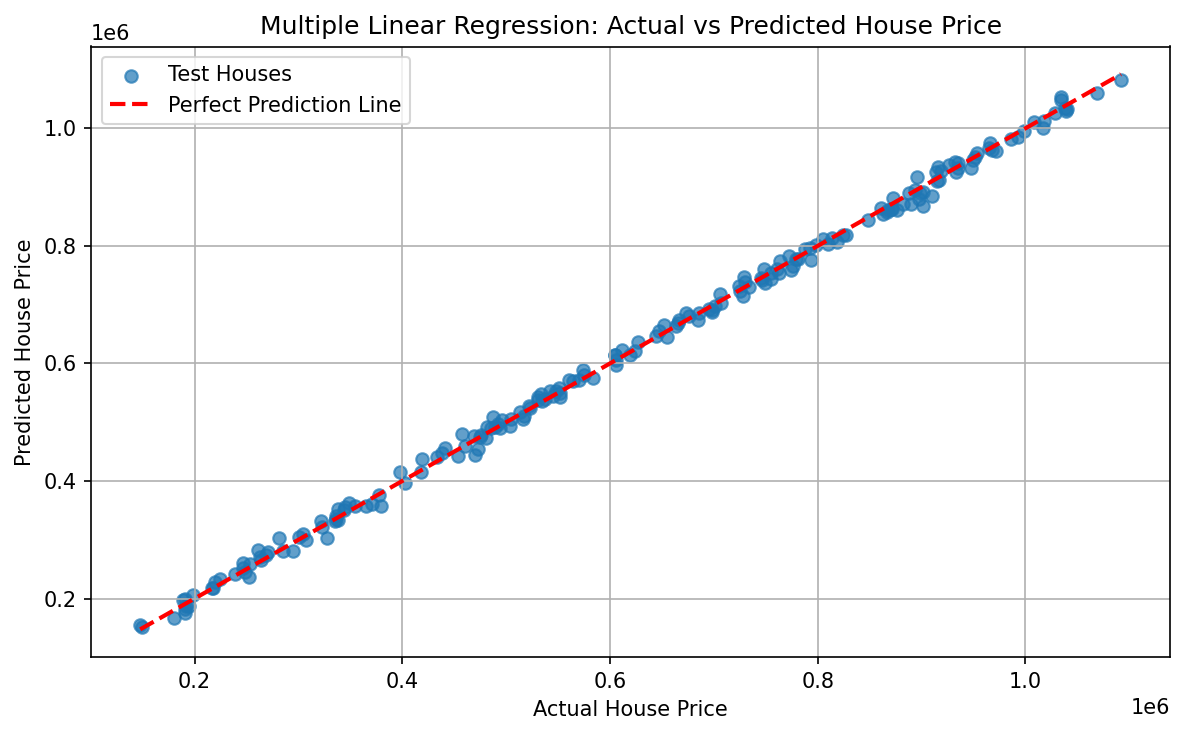

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_predict, alpha=0.7, label="Test Houses")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2, label="Perfect Prediction Line")
plt.title("Multiple Linear Regression: Actual vs Predicted House Price")
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_predict)
mse = mean_squared_error(y_test, y_predict)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_predict)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE : 8174.583599864716
MSE : 101434798.4503387
RMSE: 10071.48442139185
R² Score: 0.9984263636832067
